# ISAF — Final XGBoost Model (Four-Dimension Evaluation)

This notebook consolidates the project’s final black-box model in **XGBoost**. It brings together the useful parts of the earlier LightGBM and XGBoost work:

1. **Predictive and economic performance** — ROC-AUC, PR-AUC, Gini, KS, Brier score, accuracy, validation-selected approval threshold, P&L, and simple reject-all / approve-all references.
2. **Interpretability** — permutation importance and SHAP global, beeswarm, and local contribution views.
3. **Stability** — repeat the full fit / early-stopping / threshold / independent validation split across fixed seeds.
4. **Fairness** — group metrics for all four protected attributes, gap summaries, pairwise TOST equivalence tests, and univariate proxy association checks.

The shared `test_eval_20k.csv` IDs are removed before any split. The shared test is used once for final reporting; threshold selection and model stopping use separate partitions from the remaining training pool. Sensitive attributes are retained for fairness reporting and **excluded from model predictors by default**, matching the LightGBM protocol. Set `INCLUDE_SENSITIVE_FEATURES = True` only for a separately labeled sensitivity run.

**Run all cells from top to bottom.** Full-data mode is the default. Fast mode is for checking that the notebook runs and must not be used for final comparisons.

## 1. Imports and experiment settings

The notebook uses XGBoost’s native categorical support. SHAP is optional at import time so predictive, economic, stability, and fairness outputs can still be produced if the local SHAP installation needs repair; permutation importance remains available in that case.

In [1]:
from pathlib import Path
from itertools import combinations
import json
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    roc_auc_score, average_precision_score, roc_curve,
    brier_score_loss, accuracy_score, confusion_matrix
)
from sklearn.inspection import permutation_importance
from xgboost import XGBClassifier
import xgboost as xgb

try:
    import shap
    SHAP_AVAILABLE = True
    SHAP_IMPORT_ERROR = None
except Exception as exc:
    shap = None
    SHAP_AVAILABLE = False
    SHAP_IMPORT_ERROR = repr(exc)

warnings.filterwarnings("ignore", category=FutureWarning)

# Paths work whether Jupyter starts in the project root or MLModels/.
PROJECT_DIR = Path.cwd()
if PROJECT_DIR.name == "MLModels":
    DATA_DIR = PROJECT_DIR.parent / "data"
    OUTPUT_DIR = PROJECT_DIR
elif (PROJECT_DIR / "MLModels").is_dir():
    DATA_DIR = PROJECT_DIR / "data"
    OUTPUT_DIR = PROJECT_DIR / "MLModels"
else:
    DATA_DIR = PROJECT_DIR.parent / "data"
    OUTPUT_DIR = PROJECT_DIR
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

TRAIN_PATH = DATA_DIR / "train.csv"
EVAL_PATH = DATA_DIR / "test_eval_20k.csv"
TARGET = "loan_paid_back"  # 1 = repaid; 0 = default
ID_COL = "id"
SENSITIVE_COLS = ["gender", "marital_status", "employment_status", "education_level"]
CAT_COLS = [
    "gender", "marital_status", "education_level", "employment_status",
    "loan_purpose", "grade_subgrade"
]

# Match LightGBM's default feature policy. Protected fields are still used below
# for group metrics and association checks, but not passed to the classifier.
INCLUDE_SENSITIVE_FEATURES = False

# Full pool is the final setting. Flip to True only for a quick code check.
FAST_MODE = False
FAST_SAMPLE_SIZE = 100_000

# A four-way split keeps fitting, early stopping, threshold selection, and
# stability evaluation on disjoint rows. The final shared test stays untouched.
RANDOM_STATE = 42
STABILITY_SEEDS = [1, 10, 42, 100, 2026]
FIT_FRACTION = 0.70
EARLY_STOP_FRACTION = 0.10
THRESHOLD_FRACTION = 0.10
STABILITY_FRACTION = 0.10

# Match LightGBM's unweighted default unless a separate class-weight sensitivity
# run is requested. Weighted probabilities can have different calibration.
USE_CLASS_WEIGHT = False

N_ESTIMATORS = 1500
EARLY_STOPPING_ROUNDS = 50
THRESHOLDS = np.arange(0.01, 1.00, 0.01)
TOST_DELTA = 0.02  # equivalence margin for approval-rate differences (2 pp)
TOST_ALPHA = 0.05
MIN_GROUP_N_FOR_TOST = 30
SHAP_SAMPLE_SIZE = 1000
PERMUTATION_REPEATS = 5

## 2. Load data and verify the shared-test boundary

All 20,000 evaluation IDs must be present in the original training file and absent from the model-training pool. This assertion runs before sampling, splitting, fitting, or threshold selection.

In [2]:
train_full = pd.read_csv(TRAIN_PATH)
eval_df = pd.read_csv(EVAL_PATH)

required = {ID_COL, TARGET, "loan_amount", "interest_rate", *SENSITIVE_COLS, *CAT_COLS}
missing_train = required - set(train_full.columns)
missing_eval = required - set(eval_df.columns)
assert not missing_train, f"Missing training columns: {sorted(missing_train)}"
assert not missing_eval, f"Missing evaluation columns: {sorted(missing_eval)}"
assert train_full[ID_COL].is_unique, "Training IDs must be unique."
assert eval_df[ID_COL].is_unique, "Shared-test IDs must be unique."
assert train_full[TARGET].dropna().isin([0, 1]).all(), "Target must be binary 0/1."
assert eval_df[TARGET].dropna().isin([0, 1]).all(), "Evaluation target must be binary 0/1."

shared_ids = set(eval_df[ID_COL])
train_ids = set(train_full[ID_COL])
assert shared_ids.issubset(train_ids), "Some shared-test IDs are not in train.csv."
training_pool = train_full.loc[~train_full[ID_COL].isin(shared_ids)].copy()
assert not set(training_pool[ID_COL]).intersection(shared_ids), "Shared-test ID leakage detected."

# Align pandas category vocabularies across fit, validation, and evaluation.
# This uses feature levels only; no evaluation labels are used for fitting.
for col in CAT_COLS:
    levels = pd.Index(pd.concat([training_pool[col], eval_df[col]], ignore_index=True).dropna().unique())
    training_pool[col] = pd.Categorical(training_pool[col], categories=levels)
    eval_df[col] = pd.Categorical(eval_df[col], categories=levels)

if FAST_MODE:
    sample_idx, _ = train_test_split(
        training_pool.index,
        train_size=min(FAST_SAMPLE_SIZE, len(training_pool)),
        stratify=training_pool[TARGET],
        random_state=RANDOM_STATE,
    )
    training_pool = training_pool.loc[sample_idx].copy()

FEATURE_COLS = [c for c in training_pool.columns if c not in [ID_COL, TARGET]]
if not INCLUDE_SENSITIVE_FEATURES:
    FEATURE_COLS = [c for c in FEATURE_COLS if c not in SENSITIVE_COLS]

assert FEATURE_COLS, "No model features remain."
assert not set(FEATURE_COLS).intersection({ID_COL, TARGET})
assert INCLUDE_SENSITIVE_FEATURES or not set(FEATURE_COLS).intersection(SENSITIVE_COLS)

print(f"Original train rows: {len(train_full):,}")
print(f"Shared test rows:    {len(eval_df):,}")
print(f"Training pool rows:  {len(training_pool):,}")
print(f"ID overlap:          {len(set(training_pool[ID_COL]) & set(eval_df[ID_COL]))}")
print(f"Model features ({len(FEATURE_COLS)}): {FEATURE_COLS}")
print(f"Sensitive features included: {INCLUDE_SENSITIVE_FEATURES}")
print(f"Fast mode: {FAST_MODE}")
print(f"Repayment rate in training pool: {training_pool[TARGET].mean():.4f}")

Original train rows: 593,994
Shared test rows:    20,000
Training pool rows:  573,994
ID overlap:          0
Model features (7): ['annual_income', 'debt_to_income_ratio', 'credit_score', 'loan_amount', 'interest_rate', 'loan_purpose', 'grade_subgrade']
Sensitive features included: False
Fast mode: False
Repayment rate in training pool: 0.7988


## 3. Economic rule and reusable evaluation helpers

Approval means the estimated probability of repayment is at least the selected threshold. The threshold is chosen by maximizing validation P&L only. The shared-test P&L is calculated after that choice and is never used to tune the policy.

In [3]:
def profit_vector(y_true, approved, loan_amount, interest_rate):
    """Course rule: repaid approval earns interest; default loses 60% of principal; reject earns 0."""
    y_true = np.asarray(y_true, dtype=int)
    approved = np.asarray(approved, dtype=bool)
    loan_amount = np.asarray(loan_amount, dtype=float)
    interest_rate = np.asarray(interest_rate, dtype=float)
    return np.where(
        approved & (y_true == 1), loan_amount * interest_rate / 100.0,
        np.where(approved & (y_true == 0), -loan_amount * 0.60, 0.0),
    )


def pnl_at_threshold(y_true, probabilities, loan_amount, interest_rate, threshold):
    decisions = np.asarray(probabilities) >= threshold
    return float(profit_vector(y_true, decisions, loan_amount, interest_rate).sum())


def select_threshold(y_true, probabilities, loan_amount, interest_rate):
    rows = []
    y_arr = np.asarray(y_true, dtype=int)
    p_arr = np.asarray(probabilities, dtype=float)
    amount = np.asarray(loan_amount, dtype=float)
    rate = np.asarray(interest_rate, dtype=float)
    for threshold in THRESHOLDS:
        approved = p_arr >= threshold
        pnl = profit_vector(y_arr, approved, amount, rate).sum()
        rows.append({
            "Threshold": float(threshold),
            "P&L": float(pnl),
            "P&L per Applicant": float(pnl / len(y_arr)),
            "Approval Rate": float(approved.mean()),
        })
    table = pd.DataFrame(rows)
    best_row = table.loc[table["P&L"].idxmax()]
    return float(best_row["Threshold"]), table


def evaluate_predictions(y_true, probabilities, loan_amount, interest_rate, threshold):
    y_arr = np.asarray(y_true, dtype=int)
    p_arr = np.asarray(probabilities, dtype=float)
    decisions = (p_arr >= threshold).astype(int)
    fpr, tpr, _ = roc_curve(y_arr, p_arr)
    tn, fp, fn, tp = confusion_matrix(y_arr, decisions, labels=[0, 1]).ravel()
    pnl = profit_vector(y_arr, decisions, loan_amount, interest_rate).sum()
    approved_count = int(decisions.sum())
    return {
        "ROC-AUC": float(roc_auc_score(y_arr, p_arr)),
        "PR-AUC": float(average_precision_score(y_arr, p_arr)),
        "Gini": float(2 * roc_auc_score(y_arr, p_arr) - 1),
        "KS": float(np.max(np.abs(tpr - fpr))),
        "Brier Score": float(brier_score_loss(y_arr, p_arr)),
        "PCC / Accuracy": float(accuracy_score(y_arr, decisions)),
        "Threshold": float(threshold),
        "P&L": float(pnl),
        "P&L per Applicant": float(pnl / len(y_arr)),
        "Approval Rate": float(decisions.mean()),
        "Default Rate Among Approved": float((y_arr[decisions == 1] == 0).mean()) if approved_count else np.nan,
        "TN": int(tn), "FP": int(fp), "FN": int(fn), "TP": int(tp),
    }


def split_training_pool(seed):
    """Return fit, early-stop, threshold, and independent stability partitions."""
    fractions = np.array([FIT_FRACTION, EARLY_STOP_FRACTION, THRESHOLD_FRACTION, STABILITY_FRACTION])
    assert np.isclose(fractions.sum(), 1.0), "The four split fractions must sum to 1."
    assert np.all(fractions > 0), "Each split fraction must be positive."
    X = training_pool[FEATURE_COLS].copy()
    y = training_pool[TARGET].astype(int).copy()
    X_fit, X_rest, y_fit, y_rest = train_test_split(
        X, y, test_size=1 - FIT_FRACTION, stratify=y, random_state=seed
    )
    # Divide the remaining rows according to the configured global fractions.
    early_stop_share_of_rest = EARLY_STOP_FRACTION / (1 - FIT_FRACTION)
    X_es, X_rest2, y_es, y_rest2 = train_test_split(
        X_rest, y_rest, test_size=1 - early_stop_share_of_rest,
        stratify=y_rest, random_state=seed + 1
    )
    threshold_share_of_remainder = THRESHOLD_FRACTION / (THRESHOLD_FRACTION + STABILITY_FRACTION)
    X_thr, X_stab, y_thr, y_stab = train_test_split(
        X_rest2, y_rest2, test_size=1 - threshold_share_of_remainder,
        stratify=y_rest2, random_state=seed + 2
    )
    return X_fit, y_fit, X_es, y_es, X_thr, y_thr, X_stab, y_stab


def build_model(seed):
    positives = int((training_pool[TARGET] == 1).sum())
    negatives = int((training_pool[TARGET] == 0).sum())
    scale_pos_weight = negatives / positives if USE_CLASS_WEIGHT else 1.0
    return XGBClassifier(
        objective="binary:logistic",
        eval_metric="auc",
        n_estimators=N_ESTIMATORS,
        max_depth=5,
        learning_rate=0.05,
        min_child_weight=5,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_alpha=0.5,
        reg_lambda=5.0,
        scale_pos_weight=scale_pos_weight,
        enable_categorical=True,
        tree_method="hist",
        early_stopping_rounds=EARLY_STOPPING_ROUNDS,
        random_state=seed,
        n_jobs=-1,
    )

## 4. Train the final XGBoost model and measure stability

For each seed, four disjoint partitions are used: 70% to fit, 10% for early stopping, 10% to select the economic threshold, and 10% for an independent stability score. Seed 42 is the final model; the other seeds measure sensitivity to data partition and random initialization. No seed is chosen based on shared-test performance.

In [4]:
models = {}
splits = {}
stability_rows = []

for seed in STABILITY_SEEDS:
    (X_fit, y_fit, X_es, y_es, X_thr, y_thr, X_stab, y_stab) = split_training_pool(seed)
    model = build_model(seed)
    model.fit(
        X_fit, y_fit,
        eval_set=[(X_es, y_es)],
        verbose=False,
    )

    # Tune the operating threshold on its own held-out partition.
    p_thr = model.predict_proba(X_thr)[:, 1]
    threshold, _ = select_threshold(
        y_thr, p_thr,
        training_pool.loc[X_thr.index, "loan_amount"],
        training_pool.loc[X_thr.index, "interest_rate"],
    )

    # Score stability on a separate partition that did not select the threshold.
    p_stab = model.predict_proba(X_stab)[:, 1]
    stab_metrics = evaluate_predictions(
        y_stab, p_stab,
        training_pool.loc[X_stab.index, "loan_amount"],
        training_pool.loc[X_stab.index, "interest_rate"],
        threshold,
    )
    stability_rows.append({
        "Seed": seed,
        "Best Iteration": int(model.best_iteration) if model.best_iteration is not None else np.nan,
        **stab_metrics,
    })
    models[seed] = model
    splits[seed] = {
        "X_thr": X_thr, "y_thr": y_thr, "p_thr": p_thr,
        "X_stab": X_stab, "y_stab": y_stab,
    }
    print(f"Seed {seed}: best iteration={model.best_iteration}, threshold={threshold:.2f}, stability AUC={stab_metrics['ROC-AUC']:.4f}")

stability_runs = pd.DataFrame(stability_rows)
stability_summary = (
    stability_runs.drop(columns=["Seed", "Best Iteration"])
    .agg(["mean", "std", "min", "max"]).T
    .rename_axis("Metric").reset_index()
)

FINAL_SEED = RANDOM_STATE
final_model = models[FINAL_SEED]
final_split = splits[FINAL_SEED]
final_threshold, threshold_analysis = select_threshold(
    final_split["y_thr"], final_split["p_thr"],
    training_pool.loc[final_split["X_thr"].index, "loan_amount"],
    training_pool.loc[final_split["X_thr"].index, "interest_rate"],
)
print(f"\nFinal threshold selected on threshold-tuning split: {final_threshold:.2f}")
print(f"Final model best iteration: {final_model.best_iteration}")

Seed 1: best iteration=1463, threshold=0.83, stability AUC=0.8068
Seed 10: best iteration=1499, threshold=0.81, stability AUC=0.8117
Seed 42: best iteration=1499, threshold=0.83, stability AUC=0.8094
Seed 100: best iteration=1470, threshold=0.84, stability AUC=0.8117
Seed 2026: best iteration=1294, threshold=0.83, stability AUC=0.8128

Final threshold selected on threshold-tuning split: 0.83
Final model best iteration: 1499


## 5. Predictive and economic performance

The first validation row below is an independent internal stability partition; threshold selection used a different split. The second row is the untouched shared test. Reject-all and approve-all P&L are context-only policies, not tuned alternatives.

In [5]:
# Independent internal validation metrics for the seed-42 model.
X_valid = final_split["X_stab"]
y_valid = final_split["y_stab"]
p_valid = final_model.predict_proba(X_valid)[:, 1]
validation_metrics = evaluate_predictions(
    y_valid, p_valid,
    training_pool.loc[X_valid.index, "loan_amount"],
    training_pool.loc[X_valid.index, "interest_rate"],
    final_threshold,
)

X_eval = eval_df[FEATURE_COLS].copy()
y_eval = eval_df[TARGET].astype(int).copy()
p_eval = final_model.predict_proba(X_eval)[:, 1]
test_metrics = evaluate_predictions(
    y_eval, p_eval, eval_df["loan_amount"], eval_df["interest_rate"], final_threshold
)

metrics_table = pd.DataFrame([
    {"Dataset": "Independent validation", **validation_metrics},
    {"Dataset": "Shared test 20k", **test_metrics},
])

reject_all_pnl = float(profit_vector(
    y_eval, np.zeros(len(y_eval), dtype=bool), eval_df["loan_amount"], eval_df["interest_rate"]
).sum())
approve_all_pnl = float(profit_vector(
    y_eval, np.ones(len(y_eval), dtype=bool), eval_df["loan_amount"], eval_df["interest_rate"]
).sum())
economic_baselines = pd.DataFrame([
    {"Policy": "Reject all", "P&L": reject_all_pnl, "P&L per Applicant": reject_all_pnl / len(y_eval), "Approval Rate": 0.0},
    {"Policy": "Approve all", "P&L": approve_all_pnl, "P&L per Applicant": approve_all_pnl / len(y_eval), "Approval Rate": 1.0},
    {"Policy": "XGBoost threshold", "P&L": test_metrics["P&L"], "P&L per Applicant": test_metrics["P&L per Applicant"], "Approval Rate": test_metrics["Approval Rate"]},
])

print("\nPerformance metrics:")
display(metrics_table.round(5))
print("\nShared-test economic references:")
display(economic_baselines.round(2))


Performance metrics:


,Dataset,ROC-AUC,PR-AUC,Gini,KS,Brier Score,PCC / Accuracy,Threshold,P&L,P&L per Applicant,Approval Rate,Default Rate Among Approved,TN,FP,FN,TP
0,Independent validation,0.80941,0.93871,0.61882,0.45961,0.1240,0.68660,0.83,3.131694e+07,545.59137,0.56894,0.0734,9151,2397,15592,30260
1,Shared test 20k,0.81051,0.93949,0.62102,0.46437,0.1243,0.68365,0.83,1.120772e+07,560.38601,0.56295,0.0715,3219,805,5522,10454



Shared-test economic references:


,Policy,P&L,P&L per Applicant,Approval Rate
0,Reject all,0.00,0.00,0.00
1,Approve all,-6884561.58,-344.23,1.00
2,XGBoost threshold,11207720.24,560.39,0.56


## 6. Validation threshold curve

This plot uses only the threshold-tuning partition. The selected point is saved with the threshold analysis table.

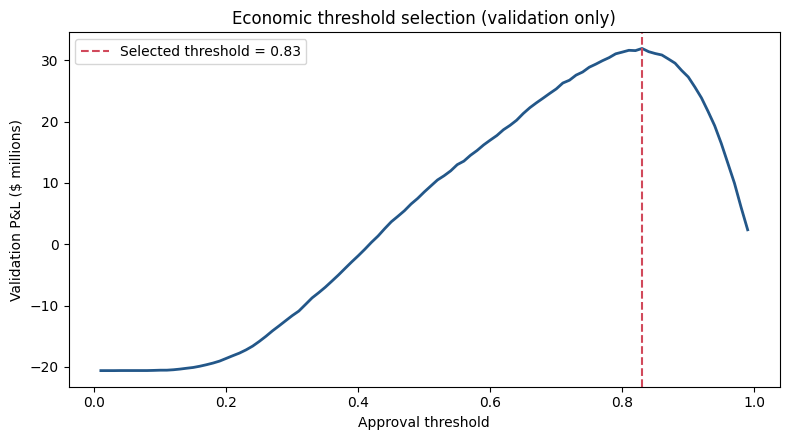

In [6]:
plt.figure(figsize=(8, 4.5))
plt.plot(threshold_analysis["Threshold"], threshold_analysis["P&L"] / 1_000_000, color="#235789", linewidth=2)
plt.axvline(final_threshold, color="#d1495b", linestyle="--", label=f"Selected threshold = {final_threshold:.2f}")
plt.xlabel("Approval threshold")
plt.ylabel("Validation P&L ($ millions)")
plt.title("Economic threshold selection (validation only)")
plt.legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "xgboost_threshold_analysis.png", dpi=160, bbox_inches="tight")
plt.show()

## 7. Interpretability — permutation importance

Permutation importance is calculated on the independent seed-42 validation partition, not the shared test. The score is ROC-AUC; a larger decrease after shuffling means the model relies more on that feature for ranking.

,Feature,Importance Mean,Importance Std
1,debt_to_income_ratio,0.18403,0.00293
2,credit_score,0.05843,0.00052
6,grade_subgrade,0.00761,0.00027
3,loan_amount,0.00467,0.00027
0,annual_income,0.00445,0.00036
4,interest_rate,0.00253,0.00034
5,loan_purpose,0.00082,0.00023


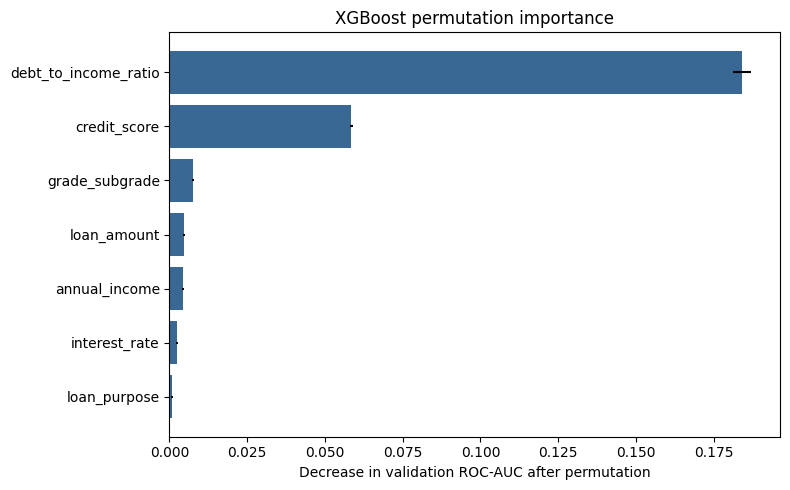

In [7]:
importance_result = permutation_importance(
    final_model,
    X_valid,
    y_valid,
    scoring="roc_auc",
    n_repeats=PERMUTATION_REPEATS,
    random_state=RANDOM_STATE,
    n_jobs=-1,
)
permutation_df = pd.DataFrame({
    "Feature": FEATURE_COLS,
    "Importance Mean": importance_result.importances_mean,
    "Importance Std": importance_result.importances_std,
}).sort_values("Importance Mean", ascending=False)
display(permutation_df.head(20).round(5))

plot_df = permutation_df.head(15).sort_values("Importance Mean")
plt.figure(figsize=(8, 5))
plt.barh(plot_df["Feature"], plot_df["Importance Mean"], xerr=plot_df["Importance Std"], color="#235789", alpha=0.9)
plt.xlabel("Decrease in validation ROC-AUC after permutation")
plt.title("XGBoost permutation importance")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "xgboost_permutation_importance.png", dpi=160, bbox_inches="tight")
plt.show()

## 8. Interpretability — SHAP global, beeswarm, and local explanation

SHAP contributions are calculated on a sample from the independent validation partition. The fallback uses XGBoost's native contribution prediction when the installed SHAP version cannot parse native categorical trees. Categorical inputs have no natural numeric order, so the waterfall emphasizes contribution size and feature name rather than assigning an artificial numeric category value.

,Feature,Mean Absolute SHAP
1,debt_to_income_ratio,0.81572
2,credit_score,0.45297
6,grade_subgrade,0.21068
3,loan_amount,0.12958
0,annual_income,0.11812
4,interest_rate,0.08346
5,loan_purpose,0.05981


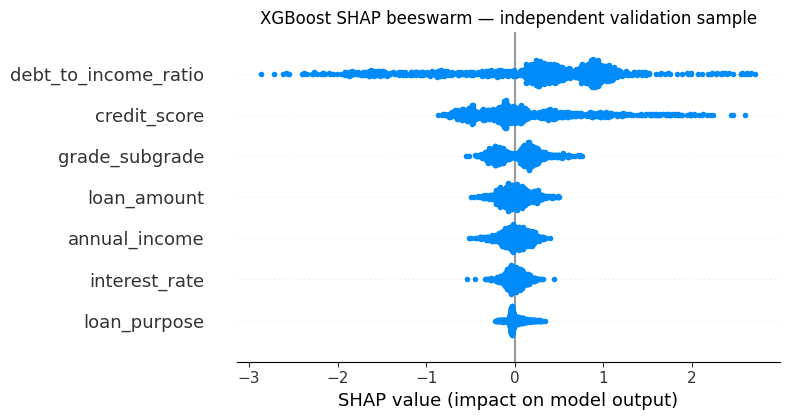

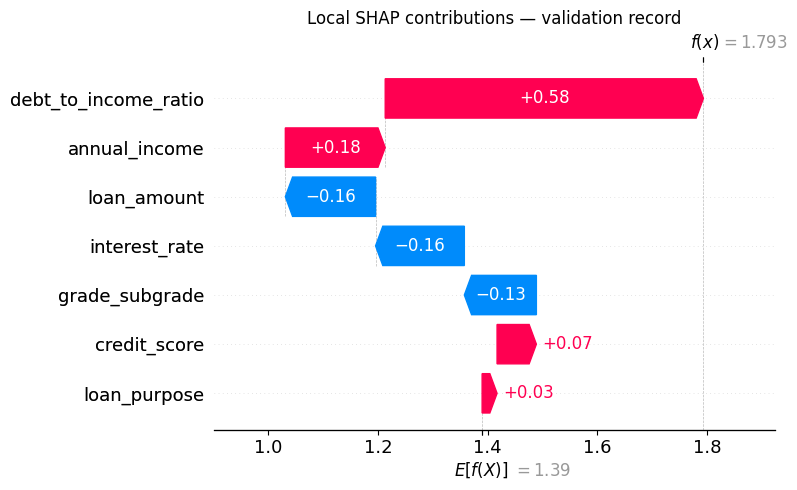

Local record ID: 107675


,Feature,SHAP Value,Absolute SHAP Value
1,debt_to_income_ratio,0.57989,0.57989
0,annual_income,0.18200,0.18200
3,loan_amount,-0.16443,0.16443
4,interest_rate,-0.16178,0.16178
6,grade_subgrade,-0.13127,0.13127
2,credit_score,0.07164,0.07164
5,loan_purpose,0.02723,0.02723


In [8]:
shap_importance_df = pd.DataFrame(columns=["Feature", "Mean Absolute SHAP"])
shap_values_array = None
shap_sample = None

if SHAP_AVAILABLE:
    shap_n = min(SHAP_SAMPLE_SIZE, len(X_valid))
    shap_sample = X_valid.sample(n=shap_n, random_state=RANDOM_STATE)
    try:
        shap_explainer = shap.TreeExplainer(final_model)
        shap_explanation = shap_explainer(shap_sample)
        shap_values_array = np.asarray(shap_explanation.values)
        shap_base_values = np.asarray(shap_explanation.base_values)
    except Exception as shap_error:
        print("TreeExplainer fallback to native XGBoost contributions:", repr(shap_error))
        dmatrix = xgb.DMatrix(shap_sample, enable_categorical=True)
        contrib = final_model.get_booster().predict(dmatrix, pred_contribs=True)
        shap_values_array = contrib[:, :-1]
        shap_base_values = contrib[:, -1]

    shap_importance_df = pd.DataFrame({
        "Feature": FEATURE_COLS,
        "Mean Absolute SHAP": np.abs(shap_values_array).mean(axis=0),
    }).sort_values("Mean Absolute SHAP", ascending=False)
    display(shap_importance_df.head(20).round(5))

    plt.figure()
    shap.summary_plot(shap_values_array, feature_names=FEATURE_COLS, show=False, max_display=20)
    plt.title("XGBoost SHAP beeswarm — independent validation sample")
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "xgboost_shap_beeswarm.png", dpi=160, bbox_inches="tight")
    plt.show()

    # Local explanation for the first sampled validation record.
    local_idx = 0
    local_exp = shap.Explanation(
        values=shap_values_array[local_idx],
        base_values=float(np.asarray(shap_base_values).reshape(-1)[local_idx]) if np.asarray(shap_base_values).ndim else float(shap_base_values),
        data=None,
        feature_names=FEATURE_COLS,
    )
    shap.plots.waterfall(local_exp, max_display=15, show=False)
    plt.title("Local SHAP contributions — validation record")
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "xgboost_shap_local_waterfall.png", dpi=160, bbox_inches="tight")
    plt.show()

    local_shap_df = pd.DataFrame({
        "Feature": FEATURE_COLS,
        "SHAP Value": shap_values_array[local_idx],
        "Absolute SHAP Value": np.abs(shap_values_array[local_idx]),
    }).sort_values("Absolute SHAP Value", ascending=False)
    print("Local record ID:", training_pool.loc[shap_sample.index[local_idx], ID_COL])
    display(local_shap_df.head(15).round(5))
else:
    print("SHAP is unavailable; permutation importance was still produced. Import error:", SHAP_IMPORT_ERROR)

## 9. Fairness — subgroup performance on the shared test

Fairness metrics are computed after fixing the validation-selected threshold. Group sizes are shown alongside rates because small groups can produce noisy estimates. Gap summaries report the worst pairwise range across observed groups.

In [9]:
def fairness_by_group(df, y_true, probabilities, threshold, sensitive_col):
    decision = (np.asarray(probabilities) >= threshold).astype(int)
    y_arr = np.asarray(y_true, dtype=int)
    rows = []
    group_values = df[sensitive_col].astype("object").fillna("<missing>").to_numpy()
    for group_name in pd.unique(group_values):
        mask = group_values == group_name
        yg, dg, pg = y_arr[mask], decision[mask], np.asarray(probabilities)[mask]
        positive = yg == 1
        negative = yg == 0
        rows.append({
            "Sensitive Attribute": sensitive_col,
            "Group": str(group_name),
            "N": int(mask.sum()),
            "Approved": int(dg.sum()),
            "Approval Rate": float(dg.mean()),
            "TPR": float(dg[positive].mean()) if positive.sum() else np.nan,
            "FPR": float(dg[negative].mean()) if negative.sum() else np.nan,
            "Precision": float(yg[dg == 1].mean()) if dg.sum() else np.nan,
            "AUC": float(roc_auc_score(yg, pg)) if len(np.unique(yg)) == 2 else np.nan,
        })
    return pd.DataFrame(rows)

fairness_details = pd.concat([
    fairness_by_group(eval_df, y_eval, p_eval, final_threshold, col)
    for col in SENSITIVE_COLS
], ignore_index=True)

fairness_rows = []
for attr, groups in fairness_details.groupby("Sensitive Attribute", sort=False):
    fairness_rows.append({
        "Sensitive Attribute": attr,
        "Demographic Parity Gap": groups["Approval Rate"].max() - groups["Approval Rate"].min(),
        "Equal Opportunity Gap": groups["TPR"].max() - groups["TPR"].min(),
        "FPR Gap": groups["FPR"].max() - groups["FPR"].min(),
        "Equalized Odds Gap": max(groups["TPR"].max() - groups["TPR"].min(), groups["FPR"].max() - groups["FPR"].min()),
        "Disparate Impact Ratio": groups["Approval Rate"].min() / groups["Approval Rate"].max() if groups["Approval Rate"].max() > 0 else np.nan,
    })
fairness_summary = pd.DataFrame(fairness_rows)

display(fairness_details.round(4))
display(fairness_summary.round(4))

,Sensitive Attribute,Group,N,Approved,Approval Rate,TPR,FPR,Precision,AUC
0,gender,Male,9727,5466,0.5619,0.6562,0.1955,0.9288,0.8163
1,gender,Female,10155,5724,0.5637,0.6524,0.2054,0.9277,0.8042
2,gender,Other,118,69,0.5847,0.6700,0.1111,0.9710,0.8756
3,marital_status,Married,9294,5232,0.5629,0.6554,0.2002,0.9278,0.8097
4,marital_status,Single,9757,5544,0.5682,0.6587,0.2029,0.9291,0.8120
5,marital_status,Divorced,762,396,0.5197,0.6039,0.1788,0.9318,0.7986
6,marital_status,Widowed,187,87,0.4652,0.5755,0.1458,0.9195,0.8164
7,employment_status,Employed,15226,9080,0.5963,0.6487,0.1655,0.9699,0.8293
8,employment_status,Retired,534,338,0.6330,0.6353,0.0000,1.0000,0.9680
9,employment_status,Unemployed,2062,596,0.2890,0.9023,0.2325,0.2634,0.9195


,Sensitive Attribute,Demographic Parity Gap,Equal Opportunity Gap,FPR Gap,Equalized Odds Gap,Disparate Impact Ratio
0,gender,0.0228,0.0176,0.0942,0.0942,0.9610
1,marital_status,0.1030,0.0832,0.0571,0.0832,0.8188
2,employment_status,0.3439,0.2670,0.2325,0.2670,0.4566
3,education_level,0.0594,0.0228,0.1841,0.1841,0.9029


## 10. Fairness — equivalence testing and proxy association checks

Pairwise TOST tests ask whether observed approval-rate differences fall within ±2 percentage points. The Holm adjustment controls family-wise error across the reported pairwise comparisons. A non-significant result means equivalence was **not established**; it does not prove inequivalence. Proxy checks are univariate associations only and cannot rule out multivariate or indirect proxy effects.

In [10]:
from scipy.stats import chi2_contingency, norm


def tost_two_proportions(approved_a, n_a, approved_b, n_b, delta=TOST_DELTA):
    """Two one-sided z tests for H1: -delta < p_a - p_b < delta."""
    p_a, p_b = approved_a / n_a, approved_b / n_b
    diff = p_a - p_b
    se = np.sqrt(p_a * (1 - p_a) / n_a + p_b * (1 - p_b) / n_b)
    if se == 0:
        p_lower = 0.0 if diff > -delta else 1.0
        p_upper = 0.0 if diff < delta else 1.0
    else:
        z_lower = (diff + delta) / se   # H1: diff > -delta
        z_upper = (diff - delta) / se   # H1: diff < +delta
        p_lower = 1 - norm.cdf(z_lower)
        p_upper = norm.cdf(z_upper)
    return float(diff), float(max(p_lower, p_upper))


def holm_adjust(p_values):
    """Holm family-wise adjusted p-values, returned in original order."""
    p_values = np.asarray(p_values, dtype=float)
    order = np.argsort(p_values)
    m = len(p_values)
    adjusted_sorted = np.maximum.accumulate((m - np.arange(m)) * p_values[order])
    adjusted_sorted = np.minimum(adjusted_sorted, 1.0)
    adjusted = np.empty(m, dtype=float)
    adjusted[order] = adjusted_sorted
    return adjusted


tost_rows = []
for attr, groups in fairness_details.groupby("Sensitive Attribute", sort=False):
    eligible = groups.loc[groups["N"] >= MIN_GROUP_N_FOR_TOST].reset_index(drop=True)
    for i, j in combinations(range(len(eligible)), 2):
        a, b = eligible.iloc[i], eligible.iloc[j]
        diff, p_value = tost_two_proportions(a["Approved"], a["N"], b["Approved"], b["N"])
        tost_rows.append({
            "Sensitive Attribute": attr,
            "Group A": a["Group"], "Group B": b["Group"],
            "N A": int(a["N"]), "N B": int(b["N"]),
            "Approval Rate Difference": diff,
            "Delta": TOST_DELTA,
            "TOST p-value": p_value,
        })

tost_results = pd.DataFrame(tost_rows)
if not tost_results.empty:
    tost_results["Holm Adjusted p-value"] = holm_adjust(tost_results["TOST p-value"])
    tost_results["Equivalent within delta"] = tost_results["Holm Adjusted p-value"] < TOST_ALPHA
    tost_results["Interpretation"] = np.where(
        tost_results["Equivalent within delta"],
        "Evidence supports equivalence within the specified margin",
        "Equivalence not established",
    )
display(tost_results.round(5))


def cramers_v(a, b):
    table = pd.crosstab(a, b)
    if min(table.shape) < 2:
        return np.nan
    chi2 = chi2_contingency(table, correction=False)[0]
    n = table.to_numpy().sum()
    return float(np.sqrt(chi2 / (n * (min(table.shape) - 1)))) if n else np.nan


def eta_squared(category, numeric):
    data = pd.DataFrame({"category": category, "numeric": numeric}).dropna()
    if len(data) == 0 or data["numeric"].var() == 0:
        return np.nan
    grand_mean = data["numeric"].mean()
    ss_between = sum(len(g) * (g.mean() - grand_mean) ** 2 for _, g in data.groupby("category", observed=True)["numeric"])
    ss_total = ((data["numeric"] - grand_mean) ** 2).sum()
    return float(ss_between / ss_total) if ss_total else np.nan


proxy_rows = []
proxy_cat_candidates = [c for c in FEATURE_COLS if c in CAT_COLS]
proxy_num_candidates = [c for c in FEATURE_COLS if c not in CAT_COLS and pd.api.types.is_numeric_dtype(training_pool[c])]
for protected in SENSITIVE_COLS:
    for candidate in proxy_cat_candidates:
        proxy_rows.append({
            "Protected Attribute": protected,
            "Candidate Feature": candidate,
            "Association Measure": "Cramer's V",
            "Association Value": cramers_v(training_pool[protected], training_pool[candidate]),
        })
    for candidate in proxy_num_candidates:
        proxy_rows.append({
            "Protected Attribute": protected,
            "Candidate Feature": candidate,
            "Association Measure": "Eta-squared",
            "Association Value": eta_squared(training_pool[protected], training_pool[candidate]),
        })
proxy_checks = pd.DataFrame(proxy_rows)
print("Univariate association checks only; they do not rule out proxy effects.")
display(proxy_checks.sort_values("Association Value", ascending=False).round(5))

,Sensitive Attribute,Group A,Group B,N A,N B,Approval Rate Difference,Delta,TOST p-value,Holm Adjusted p-value,Equivalent within delta,Interpretation
0,gender,Male,Female,9727,10155,-0.00172,0.02,0.00470,0.13628,False,Equivalence not established
1,gender,Male,Other,9727,118,-0.02280,0.02,0.52450,1.00000,False,Equivalence not established
2,gender,Female,Other,10155,118,-0.02108,0.02,0.50946,1.00000,False,Equivalence not established
3,marital_status,Married,Single,9294,9757,-0.00526,0.02,0.02013,0.56359,False,Equivalence not established
4,marital_status,Married,Divorced,9294,762,0.04326,0.02,0.89179,1.00000,False,Equivalence not established
5,marital_status,Married,Widowed,9294,187,0.09770,0.02,0.98255,1.00000,False,Equivalence not established
6,marital_status,Single,Divorced,9757,762,0.04852,0.02,0.93558,1.00000,False,Equivalence not established
7,marital_status,Single,Widowed,9757,187,0.10297,0.02,0.98788,1.00000,False,Equivalence not established
8,marital_status,Divorced,Widowed,762,187,0.05444,0.02,0.80120,1.00000,False,Equivalence not established
9,employment_status,Employed,Retired,15226,534,-0.03661,0.02,0.78297,1.00000,False,Equivalence not established


Univariate association checks only; they do not rule out proxy effects.


,Protected Attribute,Candidate Feature,Association Measure,Association Value
15,employment_status,grade_subgrade,Cramer's V,0.05230
17,employment_status,debt_to_income_ratio,Eta-squared,0.03074
14,employment_status,loan_purpose,Cramer's V,0.01496
22,education_level,grade_subgrade,Cramer's V,0.01479
8,marital_status,grade_subgrade,Cramer's V,0.01466
21,education_level,loan_purpose,Cramer's V,0.01157
1,gender,grade_subgrade,Cramer's V,0.01150
7,marital_status,loan_purpose,Cramer's V,0.01101
18,employment_status,credit_score,Eta-squared,0.00972
0,gender,loan_purpose,Cramer's V,0.00736


## 11. Export model, configuration, predictions, and evaluation tables

The JSON records the actual feature policy, split sizes, selected threshold, class-weight setting, and P&L rule. CSV and plot artifacts are written beside this notebook under `MLModels/`.

In [11]:
# Final shared-test decisions use the threshold chosen on the separate threshold split.
test_decisions = (p_eval >= final_threshold).astype(int)
prediction_output = pd.DataFrame({
    ID_COL: eval_df[ID_COL].to_numpy(),
    "Actual": y_eval.to_numpy(),
    "Predicted_Probability": p_eval,
    "Approval_Threshold": final_threshold,
    "Decision": np.where(test_decisions == 1, "Approve", "Reject"),
})

final_summary = pd.DataFrame([{
    "Model": "XGBoost",
    "Final Seed": FINAL_SEED,
    "Validation AUC": validation_metrics["ROC-AUC"],
    "Shared Test AUC": test_metrics["ROC-AUC"],
    "Shared Test PR-AUC": test_metrics["PR-AUC"],
    "Shared Test Gini": test_metrics["Gini"],
    "Shared Test KS": test_metrics["KS"],
    "Shared Test Brier Score": test_metrics["Brier Score"],
    "Shared Test PCC / Accuracy": test_metrics["PCC / Accuracy"],
    "Economic Threshold": final_threshold,
    "Shared Test P&L": test_metrics["P&L"],
    "P&L per Applicant": test_metrics["P&L per Applicant"],
    "Approval Rate": test_metrics["Approval Rate"],
    "Default Rate Among Approved": test_metrics["Default Rate Among Approved"],
    "Sensitive Features Included": INCLUDE_SENSITIVE_FEATURES,
    "Fast Mode": FAST_MODE,
}])

config = {
    "model": "XGBoost",
    "target": TARGET,
    "target_mapping": {"1": "repaid", "0": "default"},
    "shared_test_path": str(EVAL_PATH),
    "shared_test_rows": int(len(eval_df)),
    "training_pool_rows": int(len(training_pool)),
    "fit_fraction": FIT_FRACTION,
    "early_stop_fraction": EARLY_STOP_FRACTION,
    "threshold_fraction": THRESHOLD_FRACTION,
    "stability_fraction": STABILITY_FRACTION,
    "final_seed": FINAL_SEED,
    "stability_seeds": STABILITY_SEEDS,
    "fast_mode": FAST_MODE,
    "features": FEATURE_COLS,
    "sensitive_attributes": SENSITIVE_COLS,
    "include_sensitive_features": INCLUDE_SENSITIVE_FEATURES,
    "use_class_weight": USE_CLASS_WEIGHT,
    "threshold": final_threshold,
    "tost_delta": TOST_DELTA,
    "tost_alpha": TOST_ALPHA,
    "pnl_rule": {
        "approved_and_repaid": "+loan_amount * interest_rate / 100",
        "approved_and_defaulted": "-loan_amount * 0.60",
        "rejected": 0,
    },
}

# Save both the portable XGBoost model and a Python joblib copy.
final_model.save_model(str(OUTPUT_DIR / "xgboost_final_model.json"))
joblib.dump(final_model, OUTPUT_DIR / "xgboost_final_model.joblib")
with open(OUTPUT_DIR / "xgboost_final_config.json", "w", encoding="utf-8") as f:
    json.dump(config, f, indent=2, ensure_ascii=False)

metrics_table.to_csv(OUTPUT_DIR / "xgboost_metrics.csv", index=False)
final_summary.to_csv(OUTPUT_DIR / "xgboost_final_summary.csv", index=False)
economic_baselines.to_csv(OUTPUT_DIR / "xgboost_economic_baselines.csv", index=False)
threshold_analysis.to_csv(OUTPUT_DIR / "xgboost_threshold_analysis.csv", index=False)
stability_runs.to_csv(OUTPUT_DIR / "xgboost_stability_runs.csv", index=False)
stability_summary.to_csv(OUTPUT_DIR / "xgboost_stability_summary.csv", index=False)
permutation_df.to_csv(OUTPUT_DIR / "xgboost_permutation_importance.csv", index=False)
if SHAP_AVAILABLE and not shap_importance_df.empty:
    shap_importance_df.to_csv(OUTPUT_DIR / "xgboost_shap_global_importance.csv", index=False)
    local_shap_df.to_csv(OUTPUT_DIR / "xgboost_shap_local_explanation.csv", index=False)
fairness_details.to_csv(OUTPUT_DIR / "xgboost_fairness_details.csv", index=False)
fairness_summary.to_csv(OUTPUT_DIR / "xgboost_fairness_summary.csv", index=False)
tost_results.to_csv(OUTPUT_DIR / "xgboost_fairness_tost.csv", index=False)
proxy_checks.to_csv(OUTPUT_DIR / "xgboost_proxy_checks.csv", index=False)
prediction_output.to_csv(OUTPUT_DIR / "xgboost_shared_test_predictions.csv", index=False)

print("\nSaved XGBoost artifacts to:", OUTPUT_DIR.resolve())
display(final_summary.round(5))


Saved XGBoost artifacts to: /Users/oscar/VSCodeWorkspace/isaf-project/MLModels


,Model,Final Seed,Validation AUC,Shared Test AUC,Shared Test PR-AUC,Shared Test Gini,Shared Test KS,Shared Test Brier Score,Shared Test PCC / Accuracy,Economic Threshold,Shared Test P&L,P&L per Applicant,Approval Rate,Default Rate Among Approved,Sensitive Features Included,Fast Mode
0,XGBoost,42,0.80941,0.81051,0.93949,0.62102,0.46437,0.1243,0.68365,0.83,1.120772e+07,560.38601,0.56295,0.0715,False,False


## Interpretation notes for the final presentation

- Compare AUC and calibration metrics on the shared test, but explain economic utility using P&L, approval rate, and default rate among approved applicants together.
- Report threshold selection as validation-only and keep the shared-test threshold fixed.
- Present fairness metrics by group with sample sizes. Do not describe the model as broadly fair from one small gap or one successful equivalence test.
- Phrase proxy results as “no strong univariate associations were identified among the checked features” when supported; the checks do not rule out multivariate proxy effects.
- Stability P&L and approval rates are computed on independent internal partitions after a threshold was selected on a different partition. Shared-test metrics remain the final headline results.
- If `FAST_MODE=True` or `INCLUDE_SENSITIVE_FEATURES=True`, label that run clearly and do not compare it directly with the default final protocol.